# HSE 2024/2025: Mathematical Methods for Data Analysis

## Homework 5

### Contents

#### PCA, t-SNE – 4 points
* [Task 1](#task1) (1.5 points)
* [Task 2](#task2) (0.5 points)
* [Task 3](#task3) (0.5 points)
* [Task 4](#task3) (1 points)
* [Task 5](#task4) (0.5 points)

#### Clustering – 6 points
* [Task 5](#task5) (1.5 points)
* [Task 6](#task6) (1.5 points)
* [Task 7](#task7) (1.5 points)
* [Task 8](#task8) (0.5 point)
* [Task 9](#task8) (1 point)

Load the file `data_Mar_64.txt`.

In [ ]:
import pandas as pd
data = pd.read_csv('data_Mar_64.txt', header=None)
data.head()

,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
0,Acer Campestre,0.003906,0.003906,0.027344,0.033203,0.007812,0.017578,0.023438,0.005859,0.000000,...,0.011719,0.000000,0.005859,0.035156,0.027344,0.033203,0.001953,0.000000,0.017578,0.0
1,Acer Campestre,0.005859,0.013672,0.027344,0.025391,0.013672,0.029297,0.019531,0.000000,0.001953,...,0.017578,0.000000,0.021484,0.017578,0.046875,0.005859,0.003906,0.003906,0.046875,0.0
2,Acer Campestre,0.011719,0.001953,0.027344,0.044922,0.017578,0.042969,0.023438,0.000000,0.003906,...,0.035156,0.000000,0.015625,0.021484,0.056641,0.009766,0.003906,0.000000,0.015625,0.0
3,Acer Campestre,0.013672,0.011719,0.037109,0.017578,0.011719,0.087891,0.023438,0.000000,0.000000,...,0.015625,0.001953,0.021484,0.029297,0.033203,0.003906,0.000000,0.001953,0.027344,0.0
4,Acer Campestre,0.007812,0.009766,0.027344,0.025391,0.001953,0.005859,0.015625,0.000000,0.005859,...,0.023438,0.001953,0.021484,0.048828,0.056641,0.019531,0.000000,0.000000,0.013672,0.0


This [dataset](https://archive.ics.uci.edu/dataset/241/one+hundred+plant+species+leaves+data+set) consists of work carried out by James Cope, Charles Mallah, and James Orwell, Kingston University London. The Leaves were collected in the Royal Botanic Gardens, Kew, UK.

For Each feature, a 64 element vector is given per sample of leaf. One file for each 64-element feature vectors. **Each row begins with the class label**. Here is the plant leaf **classification task**. The remaining 64 elements is the feature vector.

In [ ]:
#Sixteen samples of leaf each of one-hundred plant species
data.shape

(1600, 65)

The first column is the target, put it in a separate variable.

In [ ]:
import numpy as np

X, y_name = np.array(data.iloc[:, 1:]), data.iloc[:, 0]

**Task 1. <a id="task1"></a> (1.5 points)** Let's do the following pipeline (detailed instructions will be in next cells)

- Encode your textual target.
- Split your data into train and test. Train a simple classification model without any improvements and calculate metrics.
- Then let's look at the low dimensional representations of the features and look at the classes there. We will use linear method PCA and non-linear t-SNE (t-distributed stochastic neighbor embedding). In this task we learn how to visualize data at the low dimensional space and check whether the obtained points are separable or not.

The target variable takes a text value. Use the `LabelEncoder` from `sklearn` to encode the text variable `y_name` and save the resulting values to the variable `y`.

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_name)

Split your data into **train** and **test** keeping 30% for the test.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

Train SVM with linear kernel on your data to predict target. Calculate accuracy, F-score. Also print out confusion matrix

Accuracy: 0.00625
F1 score: 0.00367032967032967


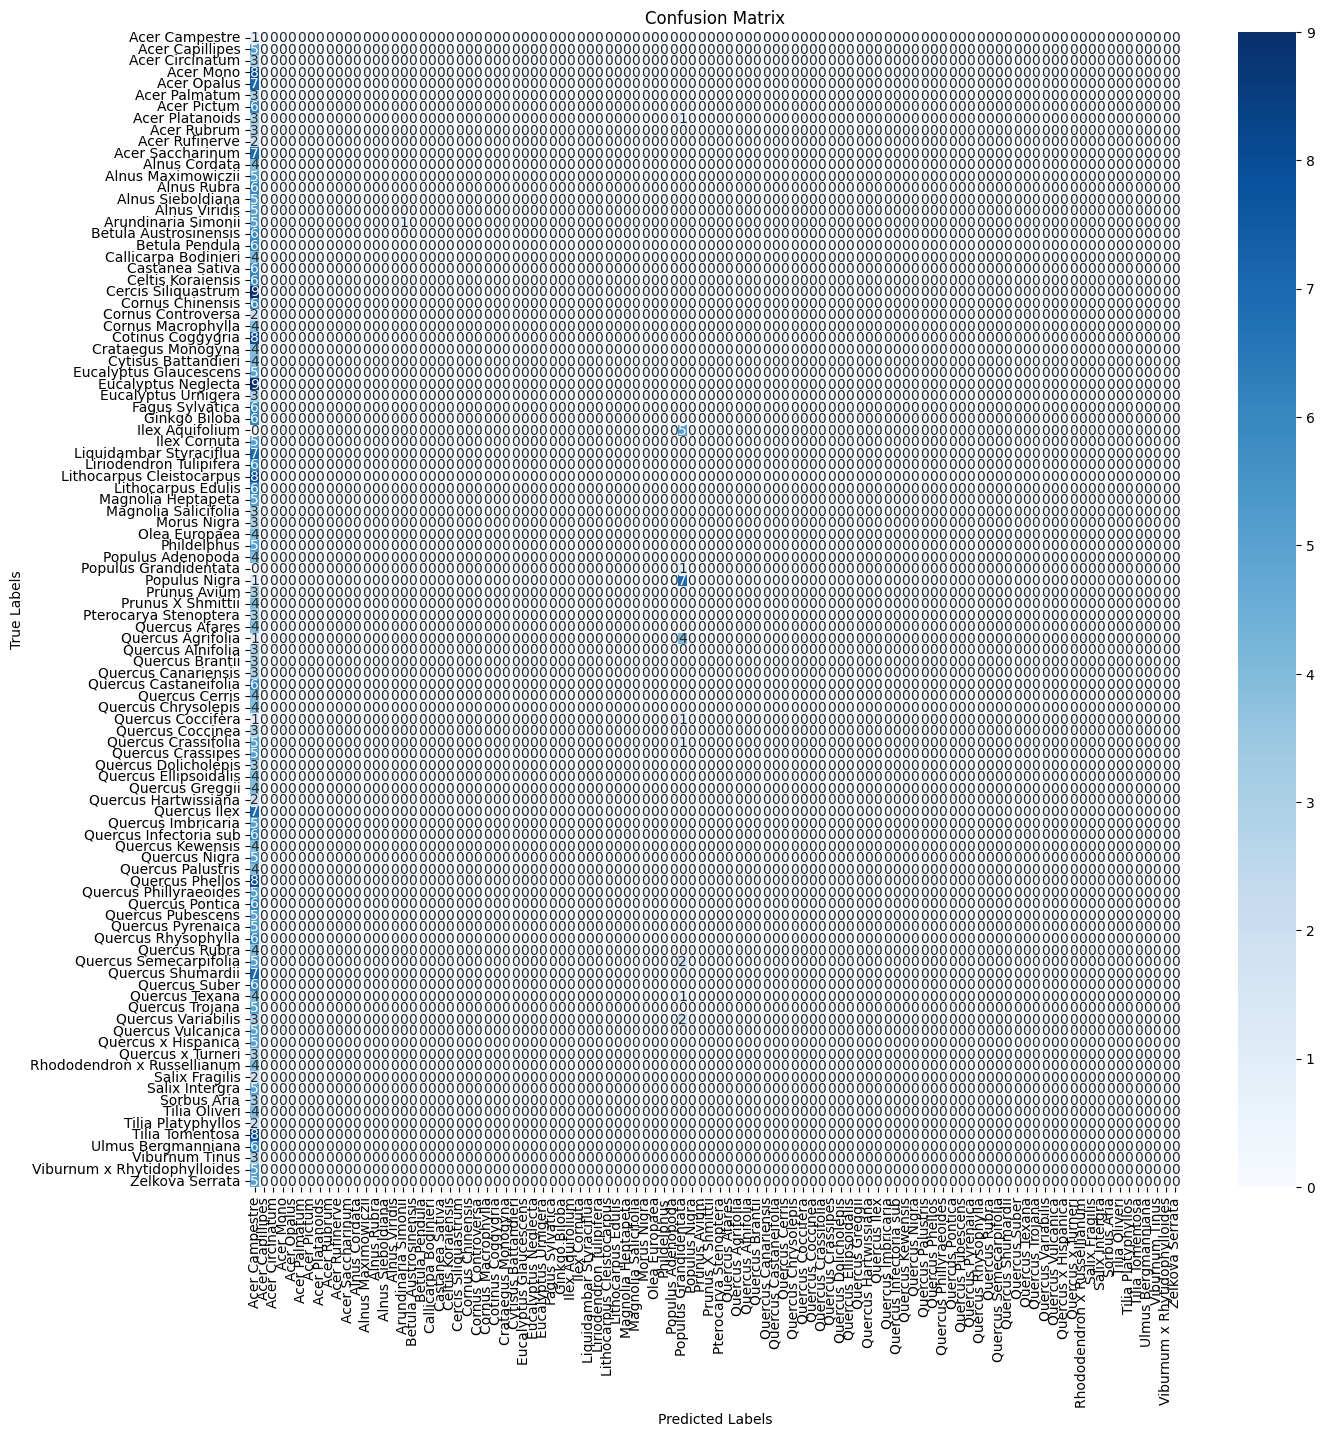

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

svm = SVC(kernel = 'linear')
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('F1 score:', f1_score(y_test, y_pred, average='macro'))
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(15, 15))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

Let's try Principal Component Analysis. Use the `PCA` method from `sklearn.decomposiion` to reduce the dimension of the feature space to two. Fix `random_state=1`

In [ ]:
from sklearn.decomposition import PCA

# Apply PCA to reduce dimensionality to 2
pca = PCA(n_components=2, random_state=1)
X_pca = pca.fit_transform(X)

Select objects that match values from 0 to 15 of the target variable `y`. Draw the selected objects in a two-dimensional feature space using the `scatter` method from `matplotlib.pyplot`. To display objects of different classes in different colors, pass `c = y[y<=15]` to the `scatter` method.

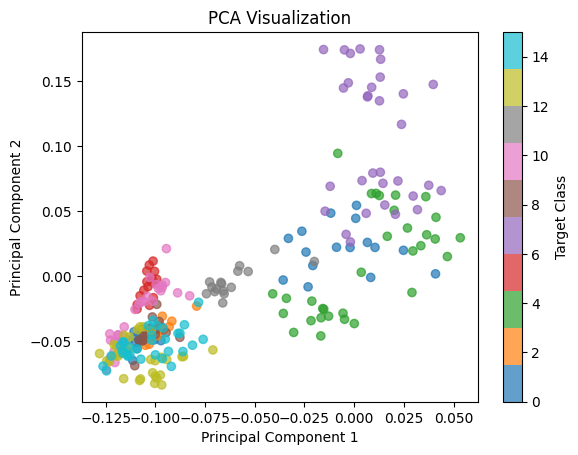

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

selected_indices = y <= 15
plt.scatter(X_pca[selected_indices, 0], X_pca[selected_indices, 1], c=y[selected_indices], cmap='tab10', alpha=0.7)
plt.colorbar(label='Target Class')
plt.title("PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()


Do the same procedure as in two previous cells, but now for the `TSNE` method from `sklearn.manifold`.

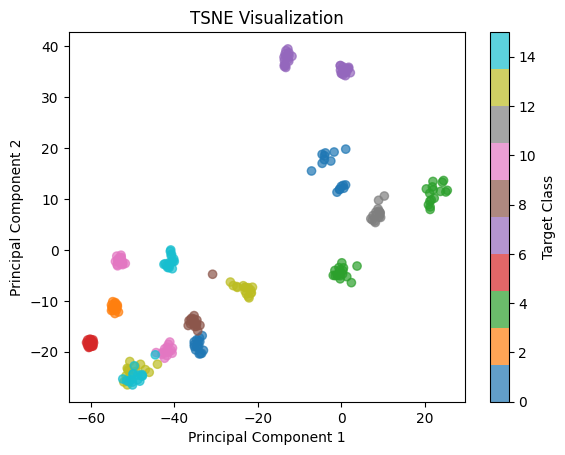

In [ ]:
from sklearn.manifold import TSNE

# Apply t-SNE to reduce dimensionality to 2
tsne = TSNE(n_components=2, random_state=1)
X_tsne = tsne.fit_transform(X)
selected_indices = y <= 15
plt.scatter(X_tsne[selected_indices, 0], X_tsne[selected_indices, 1], c=y[selected_indices], cmap='tab10', alpha=0.7)
plt.colorbar(label='Target Class')
plt.title("TSNE Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

**Task 2. <a id="task2"></a> (0.5 points)** Specify the coordinates of the object with index 2 (`X[2]`) after applying the TSNE method. Round the numbers to hundreds.

In [ ]:
cords_2_tsne = tuple(np.round(X_tsne[2], 3))
print(cords_2_tsne)

(0.567, 12.13)


**Task 3. <a id="task3"></a> (0.5 points)** Specify the coordinates of the object with index 2 (`X[2]`) after applying the PCA method. Round the numbers to hundreds.

In [ ]:
cords_2_pca = tuple(np.round(X_pca[2], 3))
print(cords_2_pca)

(-0.026, 0.034)


**Task 4. <a id="task4"></a> (1 points)** What conclusions can be drawn from the obtained images? Choose the right one(s).

1) Using the principal components method, it was possible to visualize objects on a plane and objects of different classes are visually separable

2) Using the TSNE method, it was possible to visualize objects on a plane and objects of different classes are visually separable

3) Using the TSNE and PCA methods, it was possible to visualize objects on a plane and objects of different classes are visually separable

4) Using the TSNE and PCA methods, it was possible to visualize objects on a plane and objects of different classes are not visually separable

##CONCLUSIONS:
According to obtained images we can see that:


2) Using the TSNE method, it was possible to visualize objects on a plane and objects of different classes are visually separable

**Task 5. (0.5 points)** Again try to fit your simple classifier, this time using transformed data to two-dimensional space. To do it choose the best feature representation in your opinion from two existing. Did the metrics improve?

**I have chosen both methods to compare them.**

Accuracy: 0.0020833333333333333
F1 score: 7.547169811320755e-05


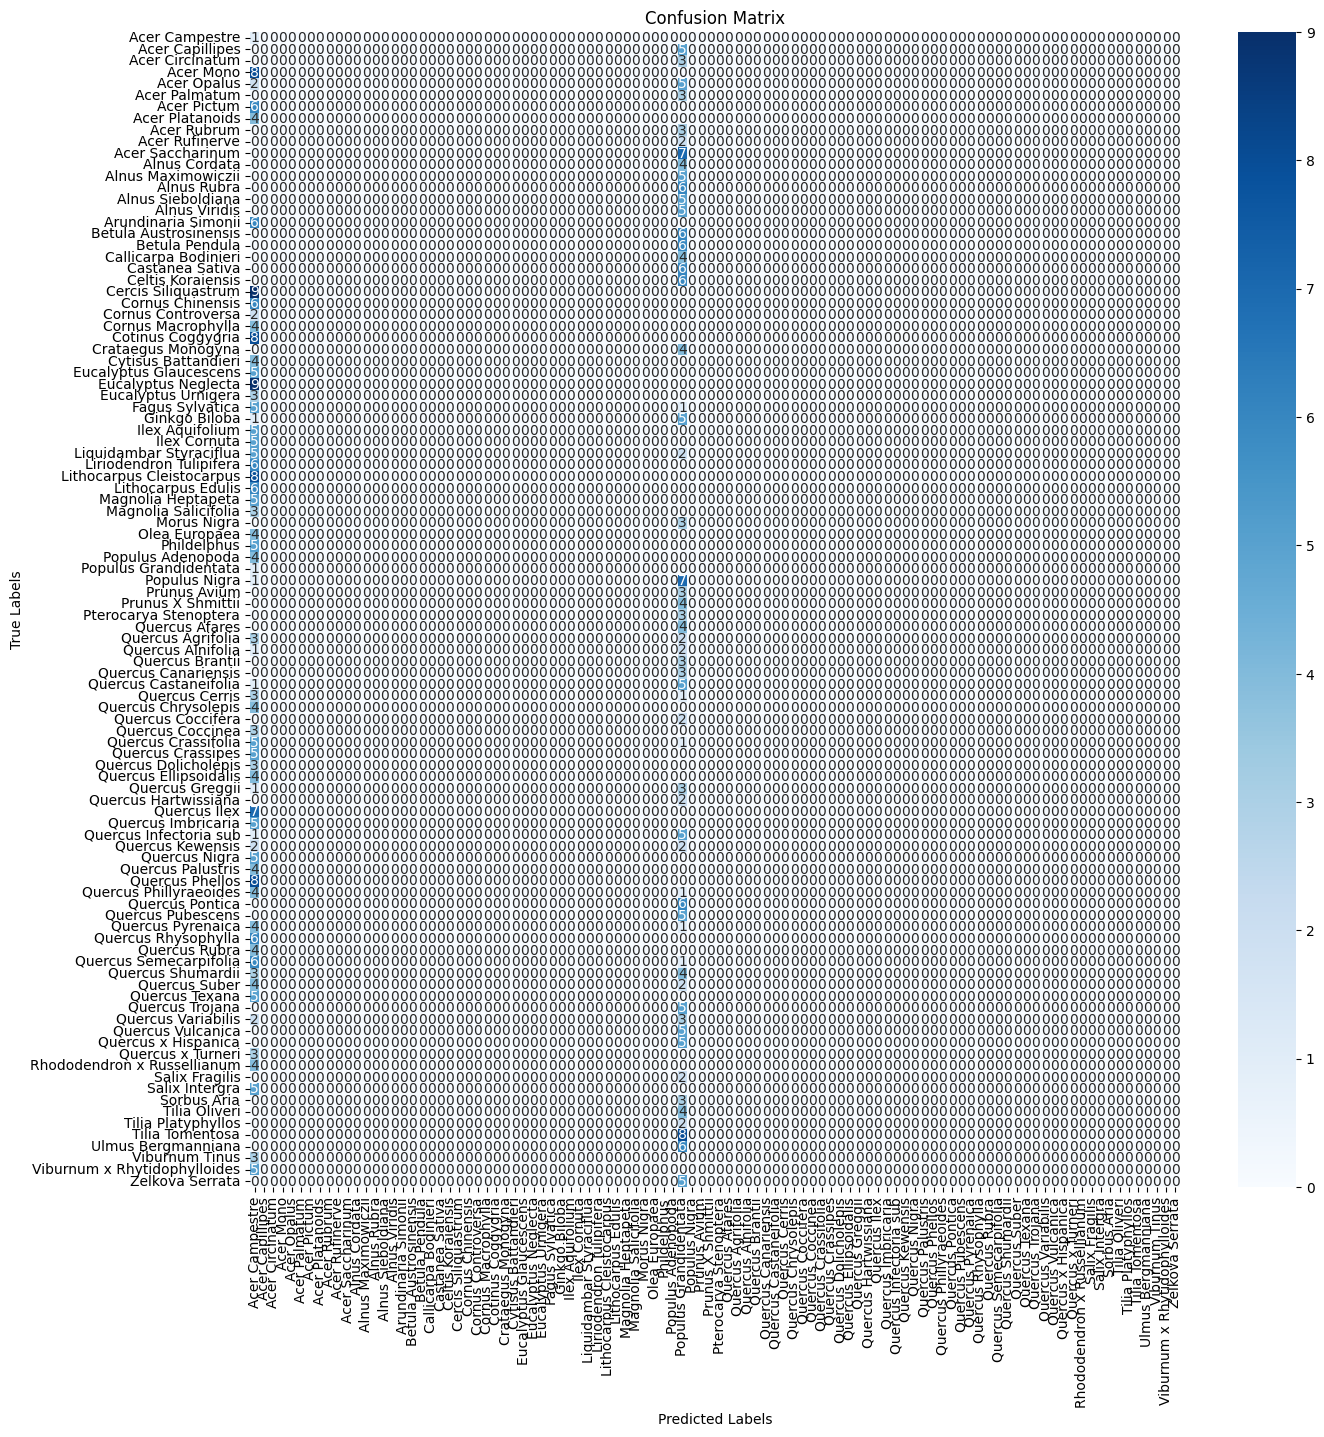

In [ ]:
#PCA
import seaborn as sns
from sklearn.metrics import confusion_matrix

X_train_trans, X_test_trans, y_train_trans, y_test_trans = train_test_split(
    X_pca, y, test_size=0.3, random_state=42
)
svm.fit(X_train_trans, y_train_trans)
y_pred_trans = svm.predict(X_test_trans)

print('Accuracy:', accuracy_score(y_test_trans, y_pred_trans))
print('F1 score:', f1_score(y_test_trans, y_pred_trans, average='macro'))
conf_matrix = confusion_matrix(y_test_trans, y_pred_trans)

plt.figure(figsize=(15, 15))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


**The metrics have not improved.**

Accuracy: 0.6770833333333334
F1 score: 0.6657892580415801


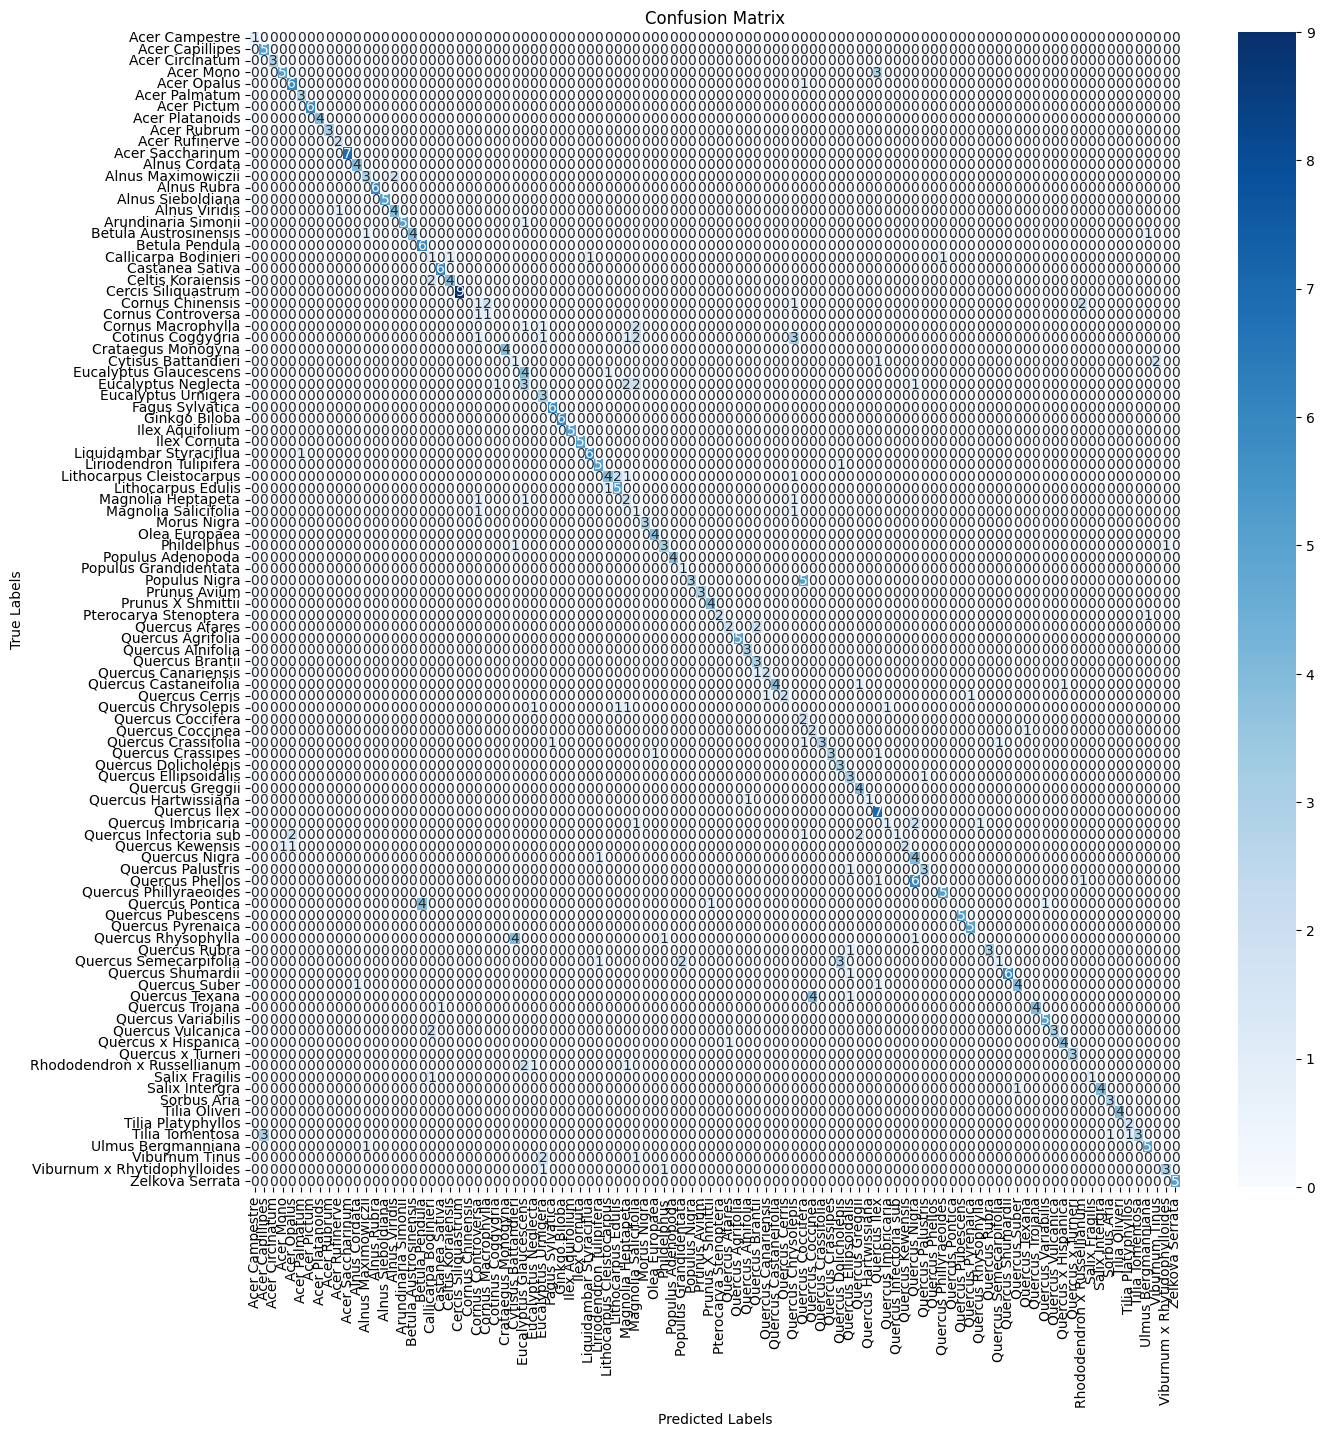

In [ ]:
#TSNE
import seaborn as sns
from sklearn.metrics import confusion_matrix

X_train_trans, X_test_trans, y_train_trans, y_test_trans = train_test_split(
    X_tsne, y, test_size=0.3, random_state=42
)
svm.fit(X_train_trans, y_train_trans)
y_pred_trans = svm.predict(X_test_trans)

print('Accuracy:', accuracy_score(y_test_trans, y_pred_trans))
print('F1 score:', f1_score(y_test_trans, y_pred_trans, average='macro'))
conf_matrix = confusion_matrix(y_test_trans, y_pred_trans)

plt.figure(figsize=(15, 15))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


**The metrics have highly improved!**

## K_means

**Task 6. <a id="task5"></a> (1.5 points)** Implement the MyKMeans class.

The class must match the template shown below. Please, add code where needed. Some guidelines are the following:

The class constructor is passed to:
- n_clusters - the number of clusters that the data will be split into

- n_iters - the maximum number of iterations that can be done in this algorithm

Realize `update_centers` and `update_labels` methods.


In the `fit` method:

- Write sequential call of `self_centers` and `self_labels`.

then in the loop by the number of iterations you need to implement:
- calculate the nearest cluster center for each object
- recalculate the center of each cluster (the average of each of the coordinates of all objects assigned to this cluster)
put the calculated new cluster centers in the `new_centers` variable

In the `predict` method:

the nearest cluster centers for `X` objects are calculated

In [ ]:
from IPython.display import clear_output
from sklearn.metrics import pairwise_distances_argmin

def plot_clust(X, centers, lables, ax):
    ax.scatter(X[:,0], X[:,1], c=lables)
    ax.scatter(centers[:,0], centers[:,1], marker='>', color='red')


class MyKMeans():
    def __init__(self, n_clusters=3, n_iters=100, seed=None):
        self.n_clusters = n_clusters
        self.labels = None
        self.centers = None
        self.n_iters = n_iters
        self.seed = 0 if seed is None else seed
        np.random.seed(self.seed)

    def update_centers(self, X):
        centers = np.array([X[self.labels == i].mean(axis=0) for i in range(self.n_clusters)])
        return centers

    def update_labels(self, X):
        labels = pairwise_distances_argmin(X, self.centers)
        return labels

    def fit(self, X):
        random_indices = np.random.choice(X.shape[0], self.n_clusters, replace=False)
        self.centers = X[random_indices]
        #self.labels = ## your code here

        for it in range(self.n_iters):
            new_labels = self.update_labels(X)
            self.labels = new_labels

            new_centers = self.update_centers(X)
            if np.allclose(self.centers.flatten(), new_centers.flatten(), atol=1e-1):
                self.centers = new_centers
                self.labels = new_labels
                print('Converge by tolerance centers')

                fig, ax = plt.subplots(1,1, figsize=(8, 6))
                plot_clust(X, new_centers, new_labels, ax)
                return 0

            self.centers = new_centers

            fig, ax = plt.subplots(1,1)
            plot_clust(X, new_centers, new_labels, ax)
            plt.pause(0.3);
            clear_output(wait=True);


        return 1

    def predict(self, X):
        labels = labels = pairwise_distances_argmin(X, self.centers)
        return labels

Generating data for clustering

In [ ]:
from sklearn import datasets
n_samples = 1000

noisy_blobs = datasets.make_blobs(n_samples=n_samples,
                             cluster_std=[1.0, 0.5, 0.5],
                             random_state=0)

In [ ]:
X, y = noisy_blobs

**Task 7. <a id="task6"></a> (1.5 points)**

7.1 Cluster noisy_blobs objects with `MyKMeans`, use the hyperparameters `n_clusters=3`, `n_iters=3`. Plot result. Specify the result label for the object with index 0.

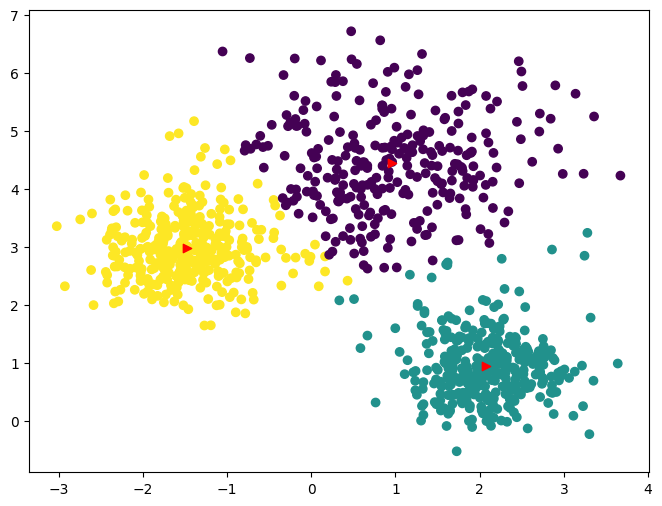

Label for object with index 0: 2


In [ ]:
kmeans = MyKMeans(n_clusters = 3, n_iters = 3, seed = 42)
kmeans.fit(X)

label_index_0 = kmeans.predict(X[[0]])
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plot_clust(X, kmeans.centers, kmeans.labels, ax)
plt.show()
print(f"Label for object with index 0: {label_index_0[0]}")

7.2 Cluster noisy_blobs objects, use the hyperparameters `n_clusters=3`, `n_iters = 100`. Plot result. Specify the result label for the object with index 0.

Converge by tolerance centers
Label for object with index 0: 0


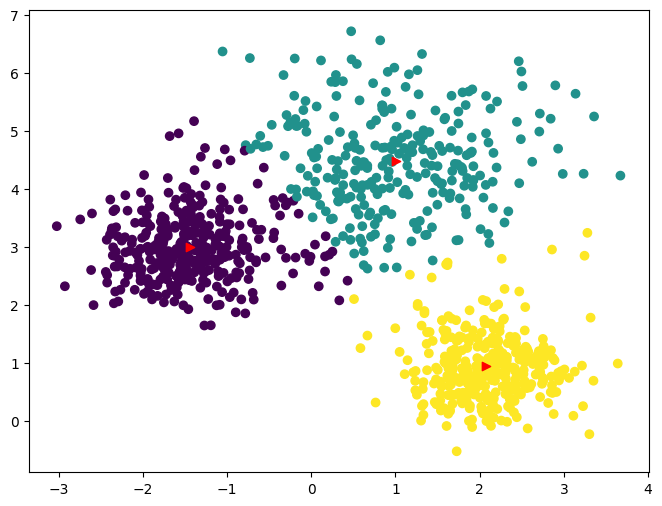

In [ ]:
kmeans_long = MyKMeans(n_clusters=3, n_iters=100)
kmeans_long.fit(X)

label_index_0_long = kmeans_long.predict(X[[0]])
print(f"Label for object with index 0: {label_index_0_long[0]}")

7.3 Calculate how many objects changed the label of the predicted cluster when changing the hyperparameter n_iters from 3 to 100

In [ ]:
labels_3_iters = kmeans.labels
labels_100_iters = kmeans_long.labels
num_of_changed = np.sum(labels_3_iters != labels_100_iters)
print(f"Number of objects that changed their predicted cluster: {num_of_changed} of {np.sum(labels_3_iters)} labels")

Number of objects that changed their predicted cluster: 990 of 1077 labels


**Task 8. <a id="task6"></a> (1.5 points)**

Using the elbow method, select the optimal number of clusters, show it on the plot. As a metric, use the sum of the squares of the distances between the data points and the centroids of the clusters assigned to them divided by number of clusters. To do this, iterate the parameter k from 2 to 50 in steps of 2.

Converge by tolerance centers


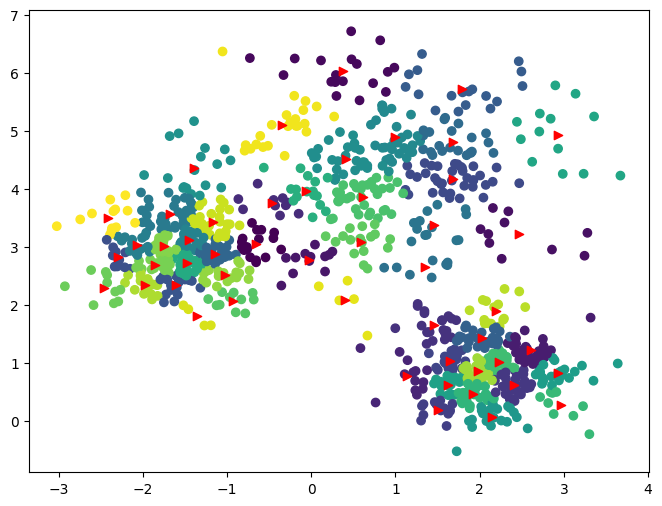

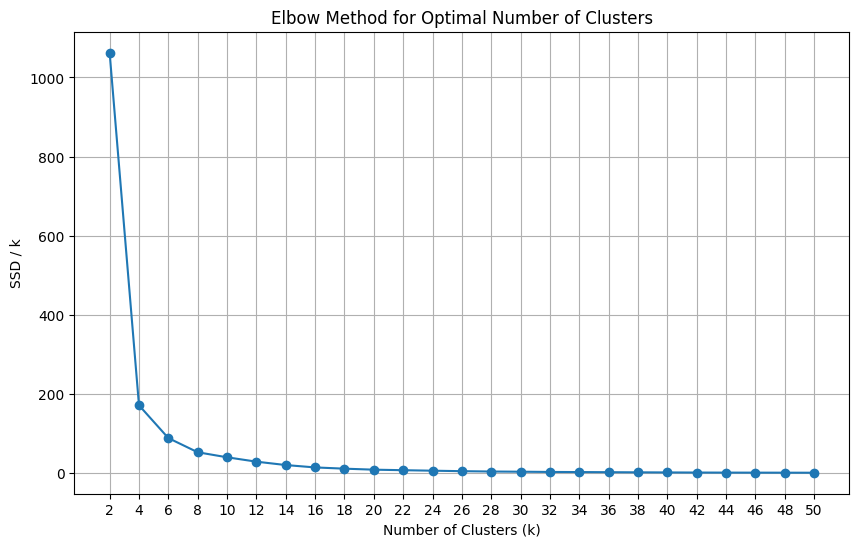

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# SSD calculations
def calculate_ssd(X, labels, centers):
    ssd = 0
    for i in range(centers.shape[0]):
        cluster_points = X[labels == i]
        ssd += np.sum((cluster_points - centers[i])**2)
    return ssd

# The elbow method
ks = range(2, 51, 2)
ssd_values = []

for k in ks:
    kmeans = MyKMeans(n_clusters=k, n_iters=100)
    kmeans.fit(X)
    ssd = calculate_ssd(X, kmeans.labels, kmeans.centers) / k
    ssd_values.append(ssd)

#The elbow curve
plt.figure(figsize=(10, 6))
plt.plot(ks, ssd_values, marker='o')
plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('SSD / k')
plt.xticks(ks)
plt.grid()
plt.show()


## DBSCAN

**Task 9. <a id="task7"></a> (0.5 points)** Cluster noisy_blobs objects using DBSCAN. Use the DBSCAN implementation from sklearn. Fix the `eps=0.3` hyperparameter. Plot result. Specify the response for the object with index 2.

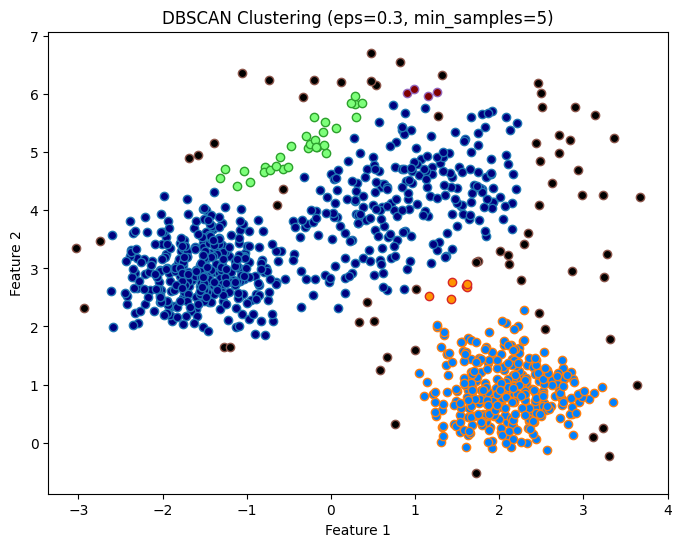

Cluster label for object with index 2: 0


In [ ]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import numpy as np

#DBSCAN clustering
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X)

# Plot
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
unique_labels = set(labels)
colors = [plt.cm.jet(float(i) / max(unique_labels)) for i in unique_labels]

for k, col in zip(unique_labels, colors):
    if k == -1:  # Outliers
        col = [0, 0, 0, 1]  # Black
    class_member_mask = (labels == k)
    ax.plot(X[class_member_mask, 0], X[class_member_mask, 1], 'o', markerfacecolor=tuple(col), markersize=6)

plt.title("DBSCAN Clustering (eps=0.3, min_samples=5)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


# Response for the object with index 2
response_index_2 = labels[2]
print(f"Cluster label for object with index 2: {response_index_2}")

**Task 10. <a id="task8"></a> (1 point)**

Try different settings of ```eps``` distances (from 0.1 to 0.5) and several values of your choice of ```min_samples```. For each setting plot results. Also output the number of clusters and outliers (objects marked as -1).

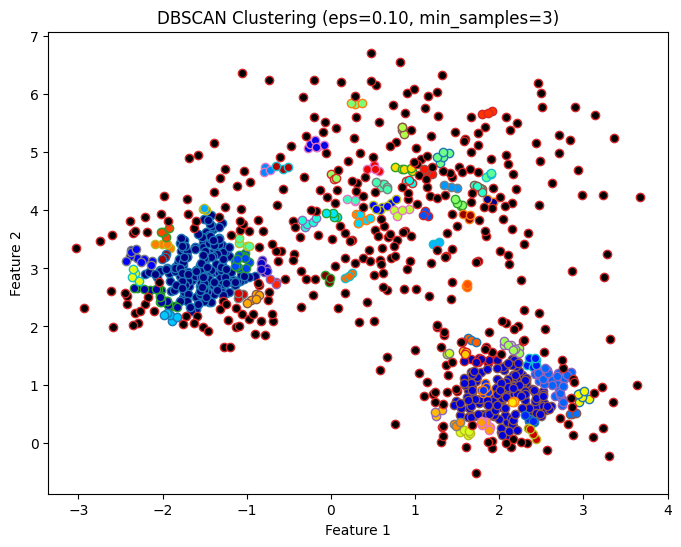

eps: 0.10, min_samples: 3, Clusters: 63, Outliers: 349


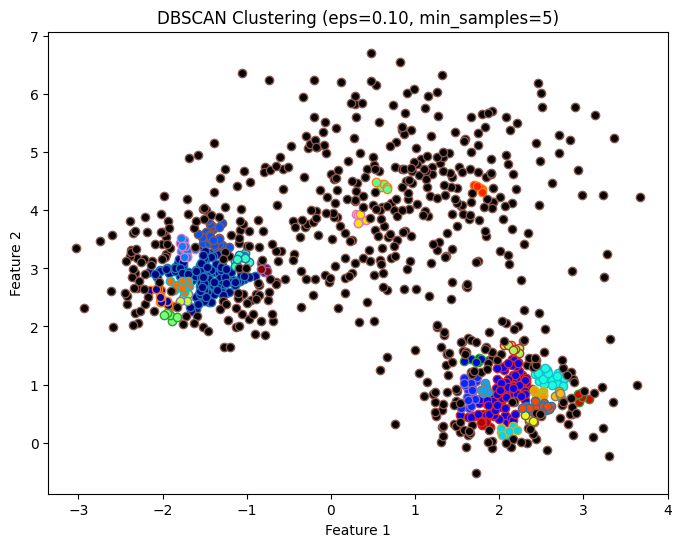

eps: 0.10, min_samples: 5, Clusters: 25, Outliers: 567


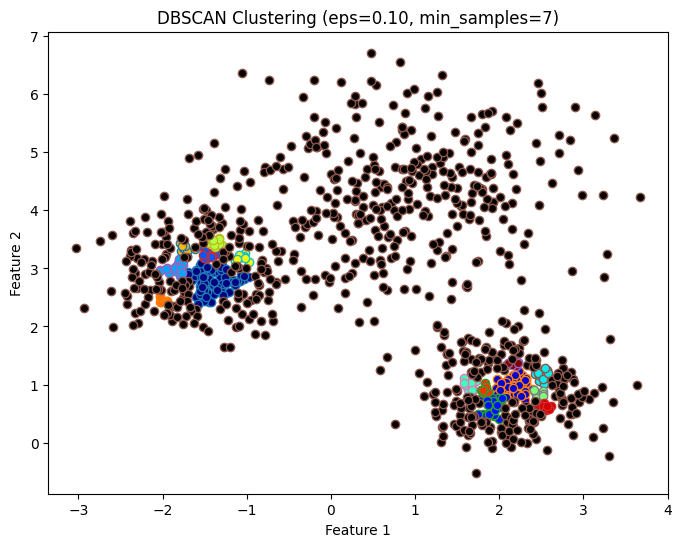

eps: 0.10, min_samples: 7, Clusters: 15, Outliers: 730


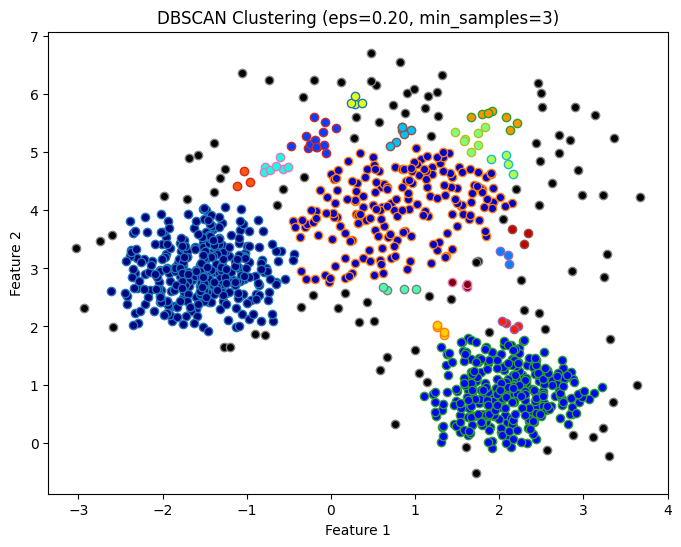

eps: 0.20, min_samples: 3, Clusters: 17, Outliers: 96


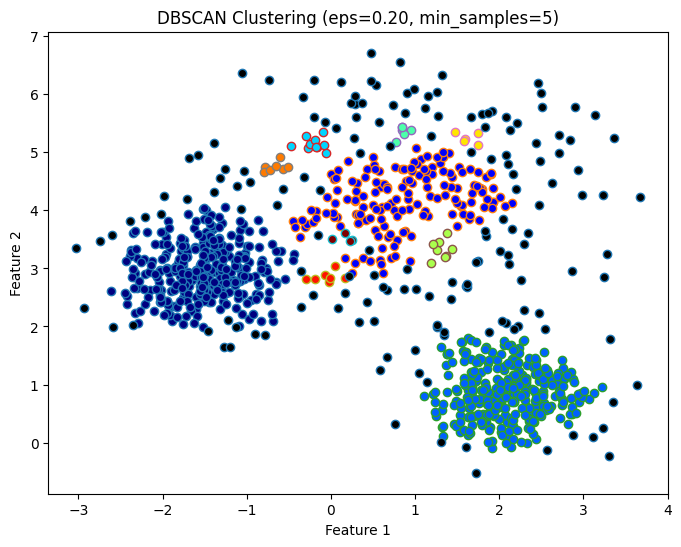

eps: 0.20, min_samples: 5, Clusters: 10, Outliers: 161


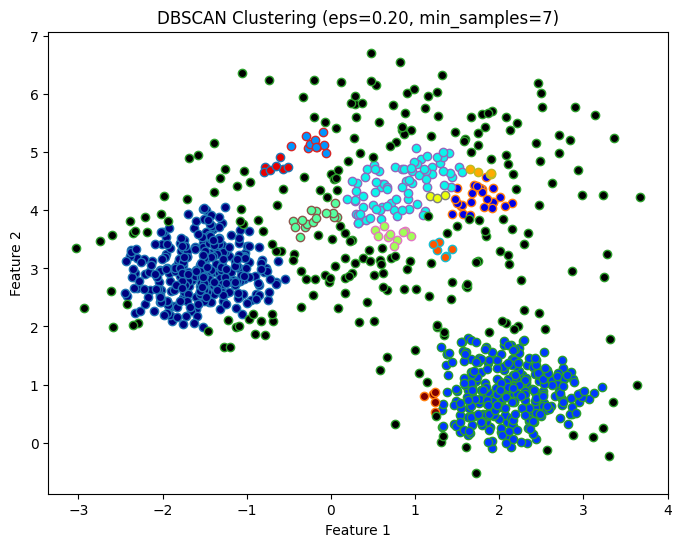

eps: 0.20, min_samples: 7, Clusters: 12, Outliers: 234


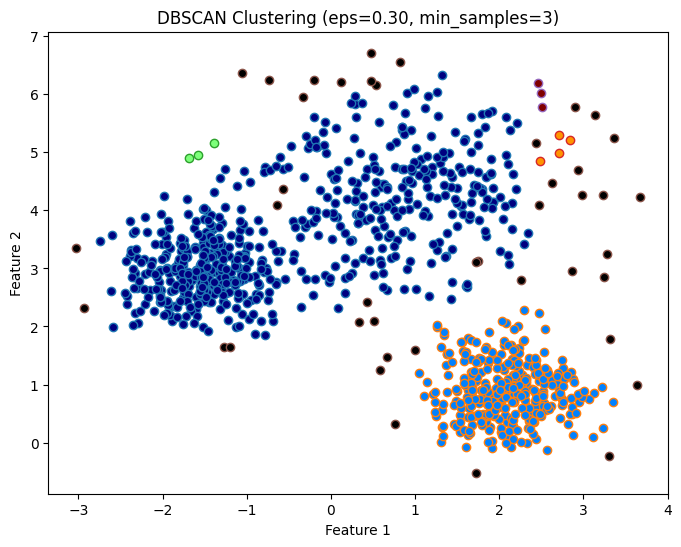

eps: 0.30, min_samples: 3, Clusters: 5, Outliers: 42


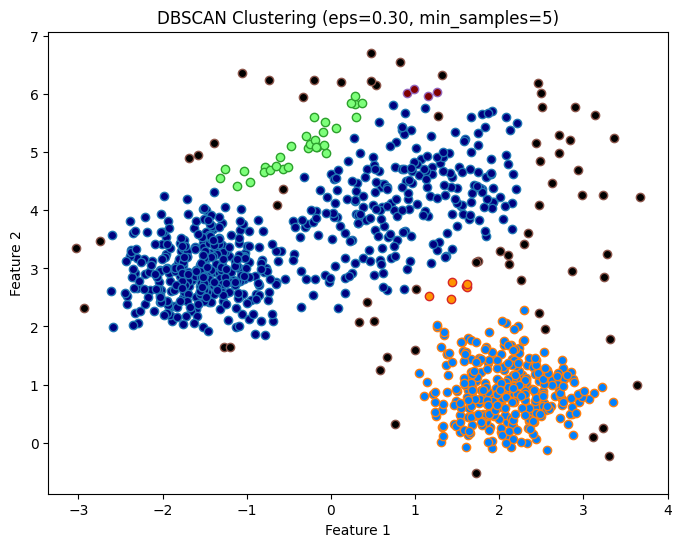

eps: 0.30, min_samples: 5, Clusters: 5, Outliers: 65


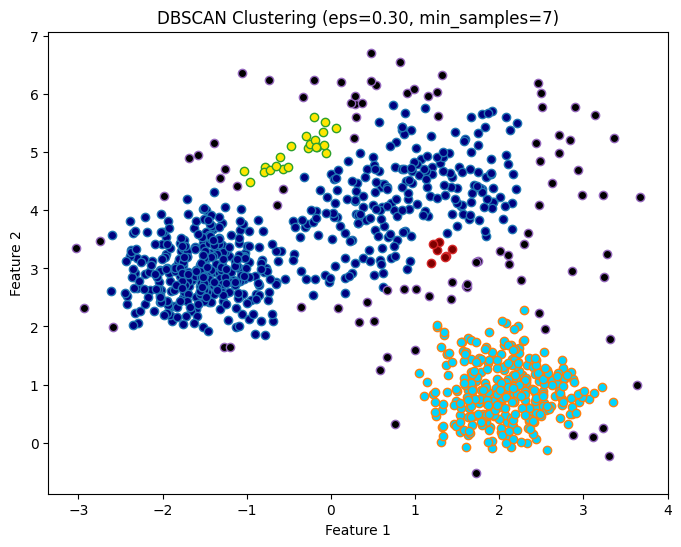

eps: 0.30, min_samples: 7, Clusters: 4, Outliers: 91


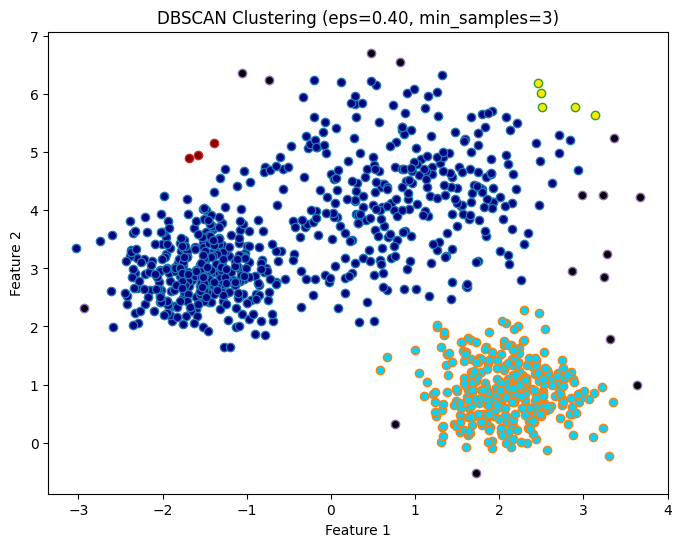

eps: 0.40, min_samples: 3, Clusters: 4, Outliers: 16


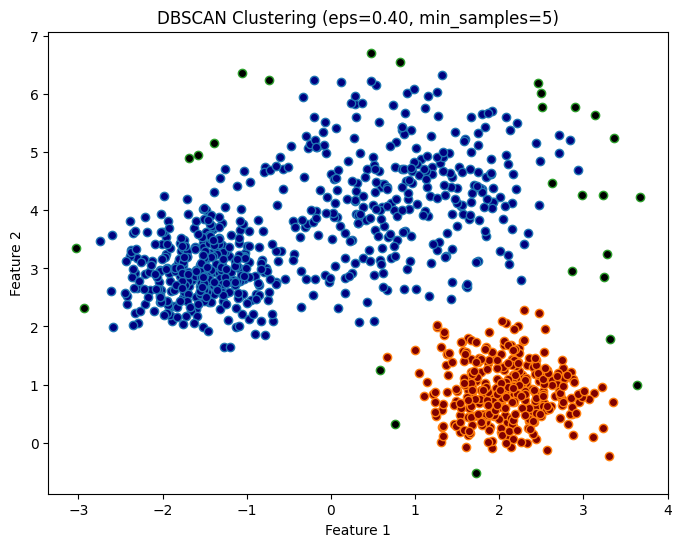

eps: 0.40, min_samples: 5, Clusters: 2, Outliers: 27


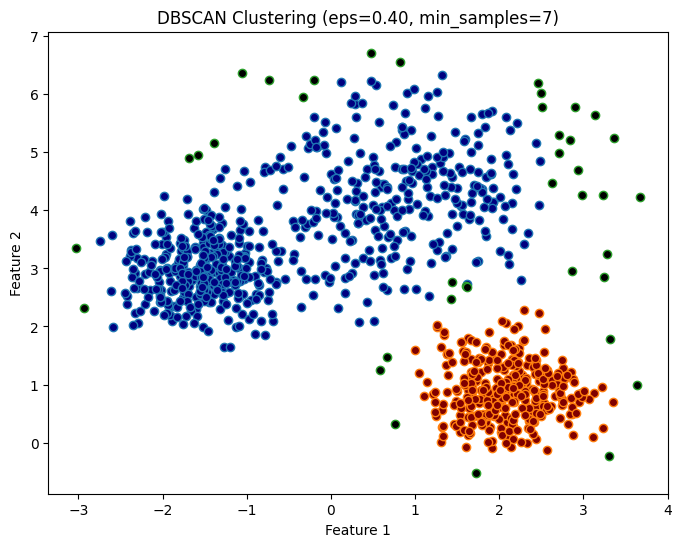

eps: 0.40, min_samples: 7, Clusters: 2, Outliers: 39


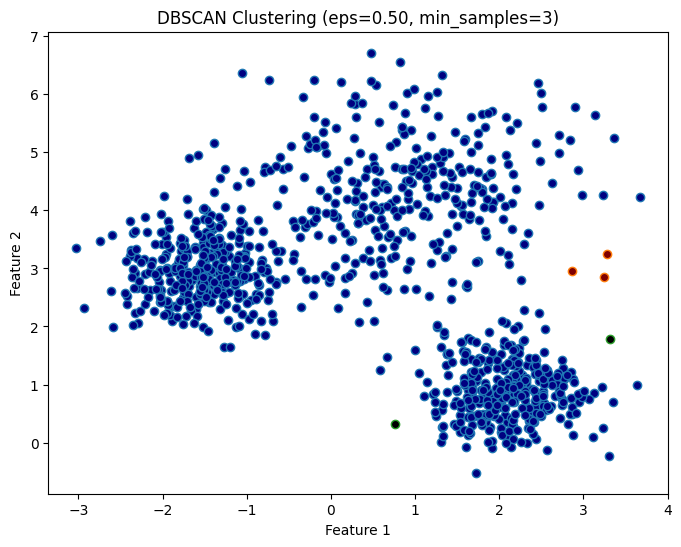

eps: 0.50, min_samples: 3, Clusters: 2, Outliers: 2


<ipython-input-23-d32e2fb06b8f>:14: RuntimeWarning: invalid value encountered in divide
  colors = [plt.cm.jet(float(i) / max(unique_labels)) for i in unique_labels]
<ipython-input-23-d32e2fb06b8f>:14: RuntimeWarning: divide by zero encountered in divide
  colors = [plt.cm.jet(float(i) / max(unique_labels)) for i in unique_labels]


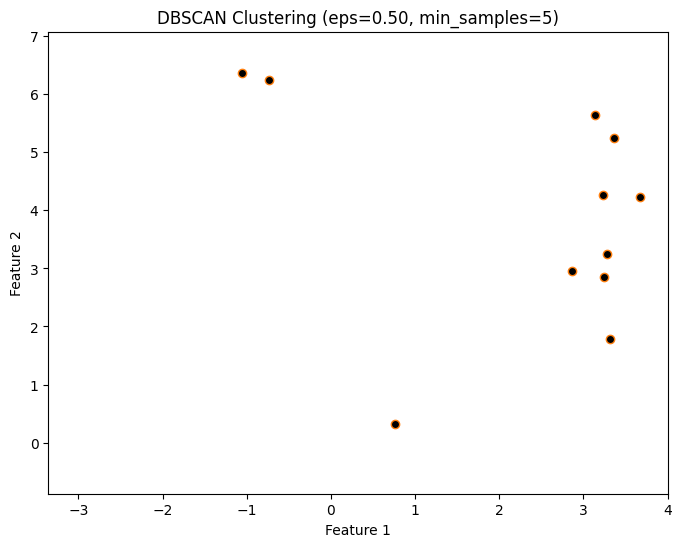

eps: 0.50, min_samples: 5, Clusters: 1, Outliers: 11


<ipython-input-23-d32e2fb06b8f>:14: RuntimeWarning: invalid value encountered in divide
  colors = [plt.cm.jet(float(i) / max(unique_labels)) for i in unique_labels]
<ipython-input-23-d32e2fb06b8f>:14: RuntimeWarning: divide by zero encountered in divide
  colors = [plt.cm.jet(float(i) / max(unique_labels)) for i in unique_labels]


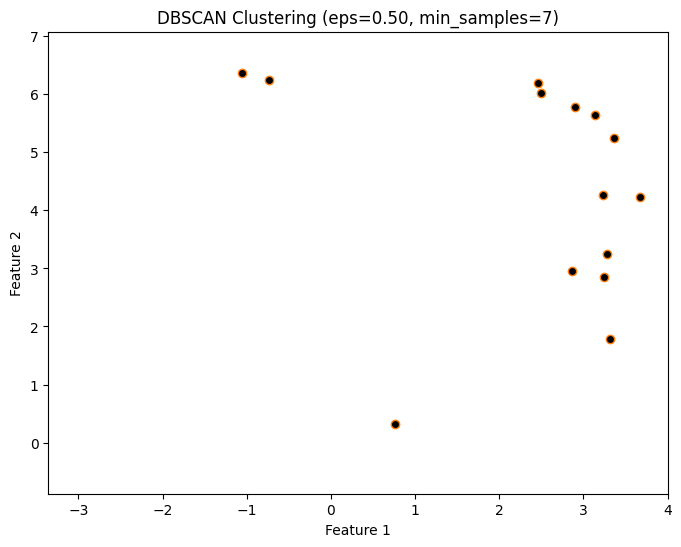

eps: 0.50, min_samples: 7, Clusters: 1, Outliers: 14


In [ ]:
eps_values = np.linspace(0.1, 0.5, 5)
min_samples_values = [3, 5, 7]

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X)

        # Count clusters and outliers
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_outliers = list(labels).count(-1)
        fig, ax = plt.subplots(1, 1, figsize=(8, 6))
        unique_labels = set(labels)
        colors = [plt.cm.jet(float(i) / max(unique_labels)) for i in unique_labels]

        for k, col in zip(unique_labels, colors):
            if k == -1:  # Outliers
                col = [0, 0, 0, 1]  # Black
            class_member_mask = (labels == k)
            ax.plot(X[class_member_mask, 0], X[class_member_mask, 1], 'o', markerfacecolor=tuple(col), markersize=6)

        plt.title(f"DBSCAN Clustering (eps={eps:.2f}, min_samples={min_samples})")
        plt.xlabel("Feature 1")
        plt.ylabel("Feature 2")
        plt.show()

        # Output the number of clusters and outliers
        print(f"eps: {eps:.2f}, min_samples: {min_samples}, Clusters: {n_clusters}, Outliers: {n_outliers}")
